In [12]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

Load the dataset, find the congestion_level for the next timestamp of the same sensor and filter for entries where the next timestamp happens in 60 minutes.

In [17]:
# Set the path to the file you'd like to load
file_path = "traffic_flow_sensors.csv"

# Load the latest version
df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, "olaflundstrom/nordcauc-urban-mobility-intelligence", file_path)

#df["congestion_level"] = df["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})
df = df[df['data_quality_flag'] == 'good']

df = df.sort_values(by=['sensor_id', 'timestamp'])
 
df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]
#df = df[df['duration_to_next'].dt.total_seconds() / 60 < 120]
#df = df.dropna(subset=['future_congestion_level'])

df = df.drop(columns=['next_timestamp', 'duration_to_next'])

C:\Users\Simon\AppData\Local\Temp\ipykernel_15840\1469095763.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS, "olaflundstrom/nordcauc-urban-mobility-intelligence", file_path)


In [145]:
df['data_quality_flag'].value_counts()

data_quality_flag
good    1901
Name: count, dtype: int64

In [83]:
print(df_processed.info())
print(df_processed['is_thunderstorm'].value_counts())
print(df_processed['is_light_snow'].value_counts())
print(df_processed['is_heavy_snow'].value_counts())

<class 'pandas.DataFrame'>
Index: 2070 entries, 165398 to 11130
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hour                     2070 non-null   float64
 1   day_of_week              2070 non-null   str    
 2   is_weekend               2070 non-null   bool   
 3   is_public_holiday        2070 non-null   bool   
 4   season                   2070 non-null   str    
 5   road_type                2070 non-null   str    
 6   speed_limit_kmh          2070 non-null   float64
 7   lane_count               2070 non-null   float64
 8   vehicle_count_15min      2070 non-null   float64
 9   avg_speed_kmh            2070 non-null   float64
 10  congestion_level         2070 non-null   str    
 11  occupancy_rate           2070 non-null   float64
 12  truck_count_15min        2070 non-null   float64
 13  temperature_c            2070 non-null   float64
 14  precipitation_mm         2070 non-

The following columns were removed from the dataset:
* sensor_id: Would not make the model generic
* city: Would not make the model generic
* country: Would not make the model generic
* district: Would not make the model generic
* timestamp: Information covered by more specific columns (e.g. hour or is_weekend)
* date: Information covered by more specific columns
* latitude: Unlikely to be useful
* longitude: Unlikely to be useful
* ev_count_15min: Unlikely to be useful
* ai_predicted_volume: Not part of our problem
* ai_predicted_congestion: Not part of our problem
* ai_model_version: Not part of our problem
* data_quality_flag: We decided to only use good quality data so the column was removed

In [24]:
df_processed = df[df["data_quality_flag"] == "good"]
df_processed = df_processed.drop(columns=["sensor_id", "city", "country", "district", "timestamp", "date", "latitude", "longitude", "ev_count_15min", "ai_predicted_volume", "ai_predicted_congestion", "ai_model_version", "data_quality_flag"])

#bool_cols = df_processed.select_dtypes(include=['bool']).columns
#df_processed[bool_cols] = df_processed[bool_cols].astype(int)

#for col in df_processed.select_dtypes(include=['object', 'string']).drop(columns='future_congestion_level').columns:
#    df_processed[col] = df_processed[col].astype('category').cat.codes

numeric_cols = df_processed.select_dtypes(include='number').columns

scaler = MinMaxScaler()
df_processed[numeric_cols] = scaler.fit_transform(df_processed[numeric_cols])

In [25]:
#x = df_processed.drop(columns=["future_congestion_level"])
cols = ['hour', 'is_weekend', 'avg_speed_kmh', 'vehicle_count_15min', 'occupancy_rate', 'precipitation_mm']
x = df_processed[cols]
x['is_light_snow'] = (df_processed['weather_condition'] == 'light_snow')
y = df_processed["future_congestion_level"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

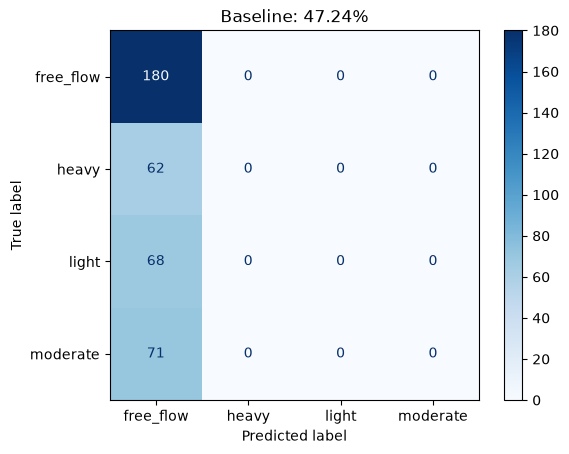

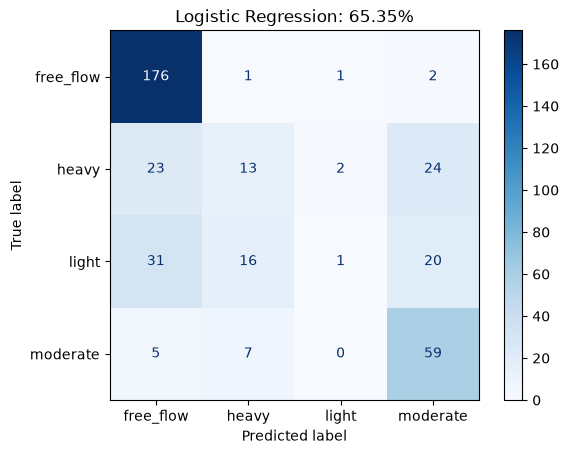

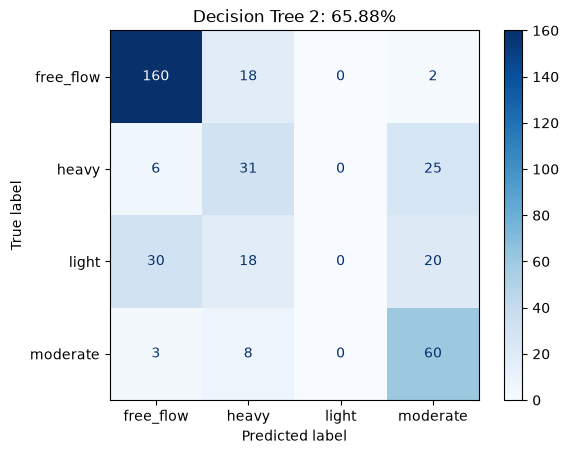

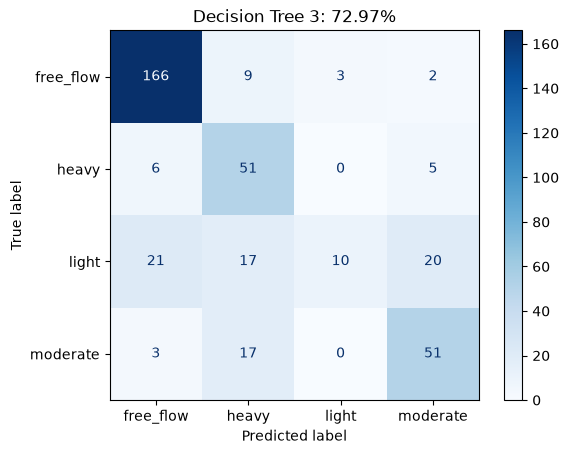

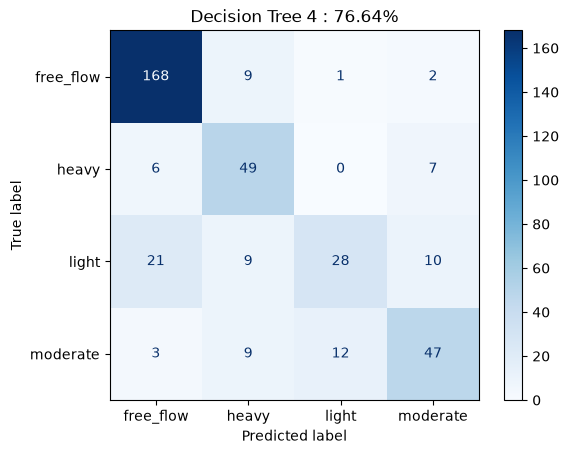

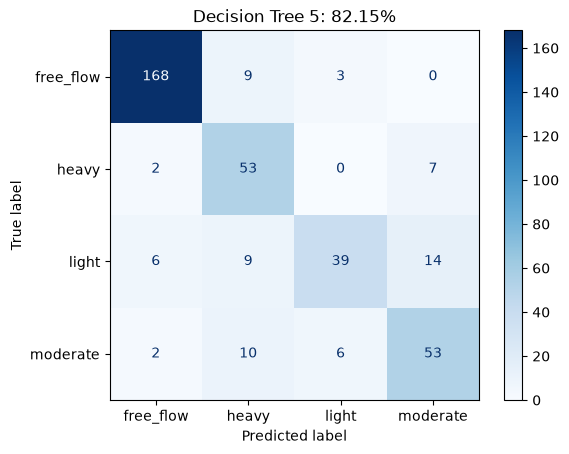

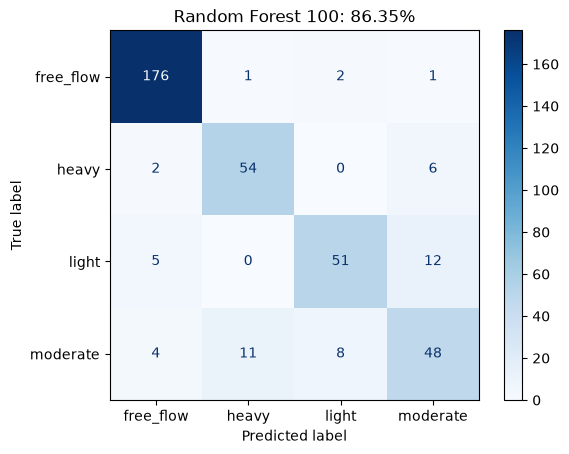

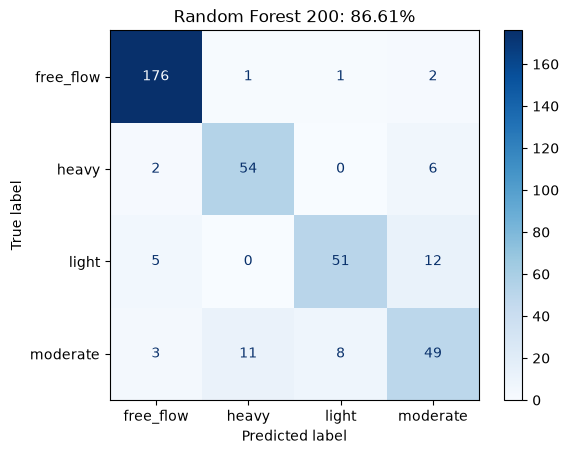

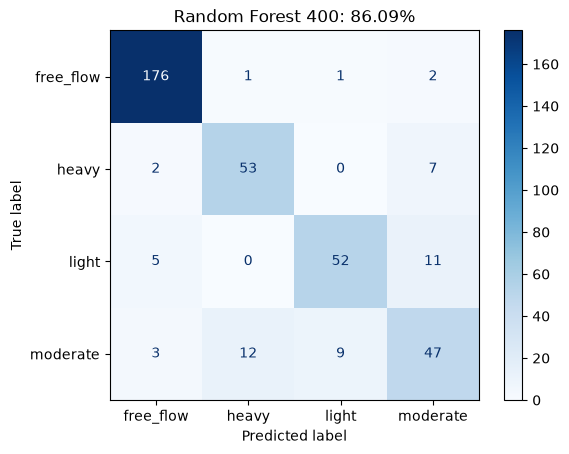

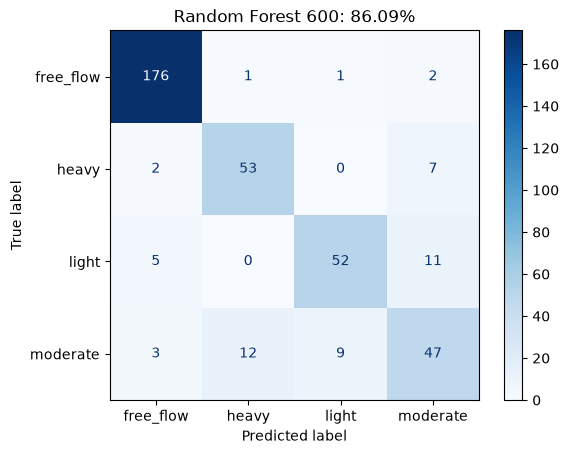

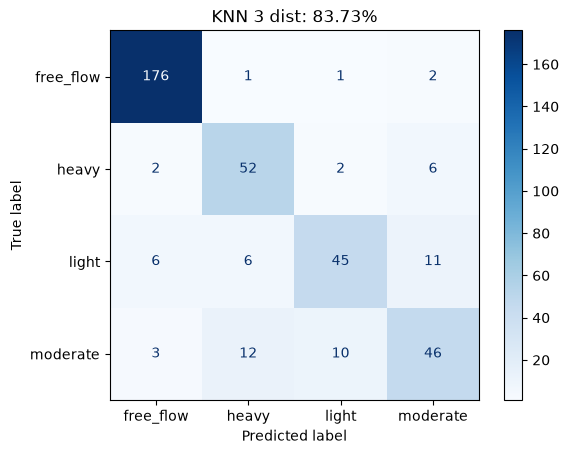

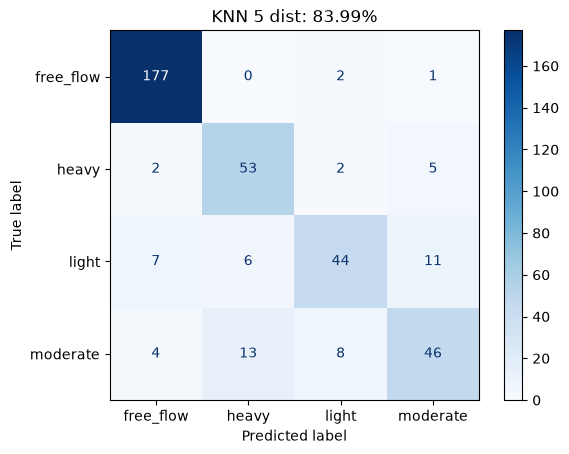

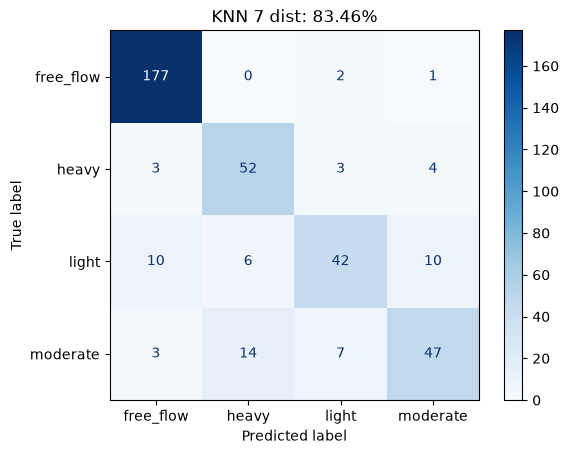

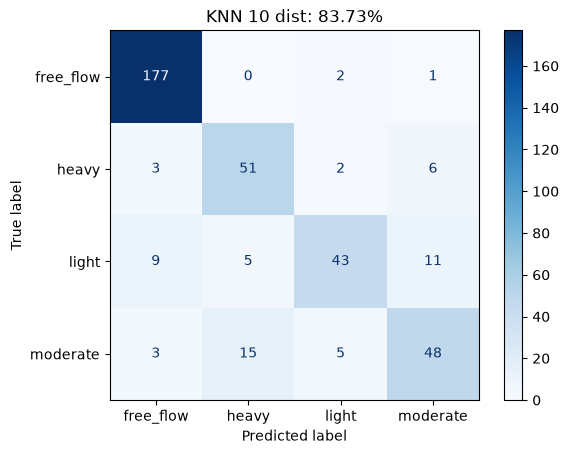

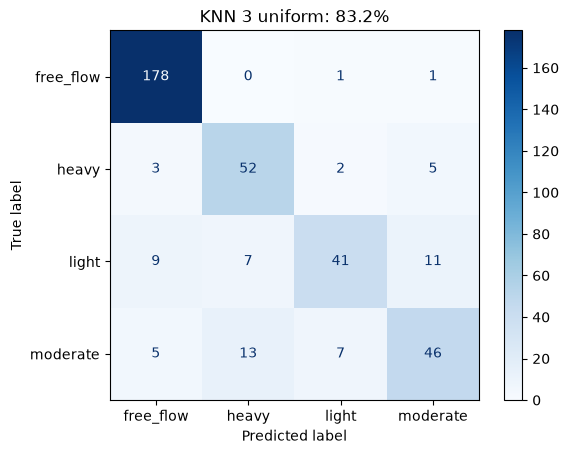

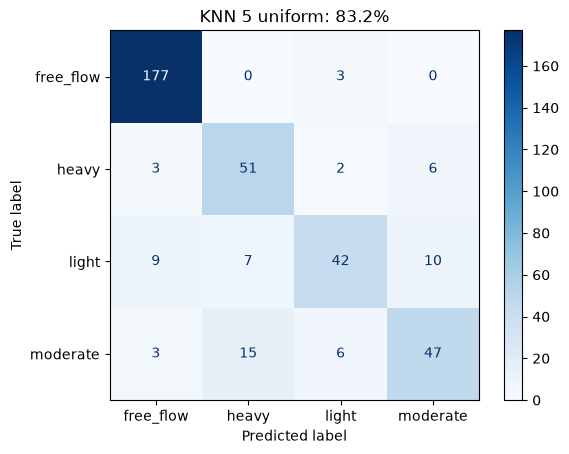

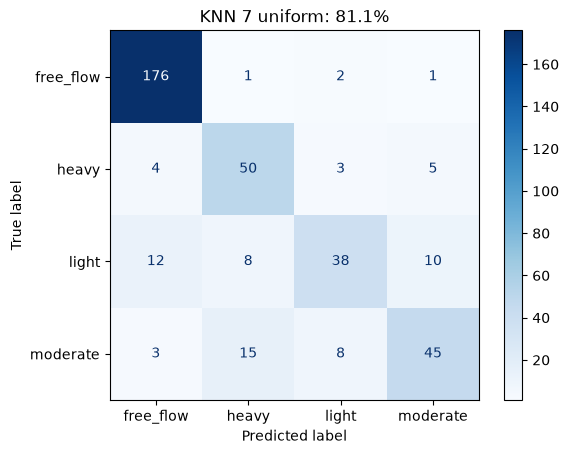

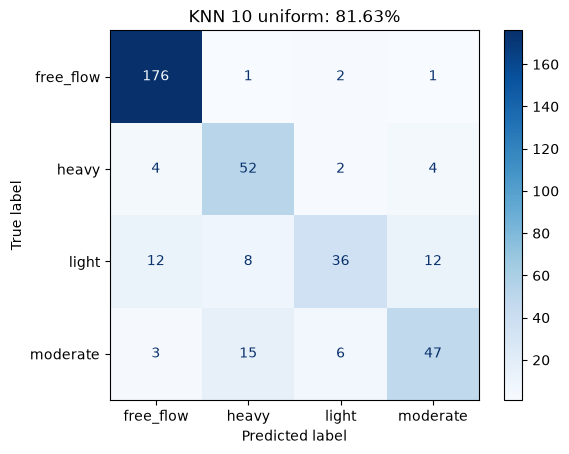

In [26]:
models = {
    'Baseline': DummyClassifier(strategy="most_frequent").fit(x_train, y_train),
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree 2': DecisionTreeClassifier(max_depth=2, random_state=42),
    'Decision Tree 3': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Decision Tree 4 ': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Decision Tree 5': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest 100': RandomForestClassifier(n_estimators=100,random_state=42),
    'Random Forest 200': RandomForestClassifier(n_estimators=200,random_state=42),
    'Random Forest 400': RandomForestClassifier(n_estimators=400,random_state=42),
    'Random Forest 600': RandomForestClassifier(n_estimators=600,random_state=42),
    'KNN 3 dist': KNeighborsClassifier(n_neighbors=3,weights='distance'),
    'KNN 5 dist': KNeighborsClassifier(n_neighbors=5,weights='distance'),
    'KNN 7 dist': KNeighborsClassifier(n_neighbors=7,weights='distance'),
    'KNN 10 dist': KNeighborsClassifier(n_neighbors=10,weights='distance'),
    'KNN 3 uniform': KNeighborsClassifier(n_neighbors=3,weights='uniform'),
    'KNN 5 uniform': KNeighborsClassifier(n_neighbors=5,weights='uniform'),
    'KNN 7 uniform': KNeighborsClassifier(n_neighbors=7,weights='uniform'),
    'KNN 10 uniform': KNeighborsClassifier(n_neighbors=10,weights='uniform'),
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    ConfusionMatrixDisplay.from_estimator(model, x_test, y_test,cmap='Blues')

    plt.title(f'{name}: {round(accuracy_score(y_test, y_pred) * 100, 2)}%')
    plt.show()

<Axes: >

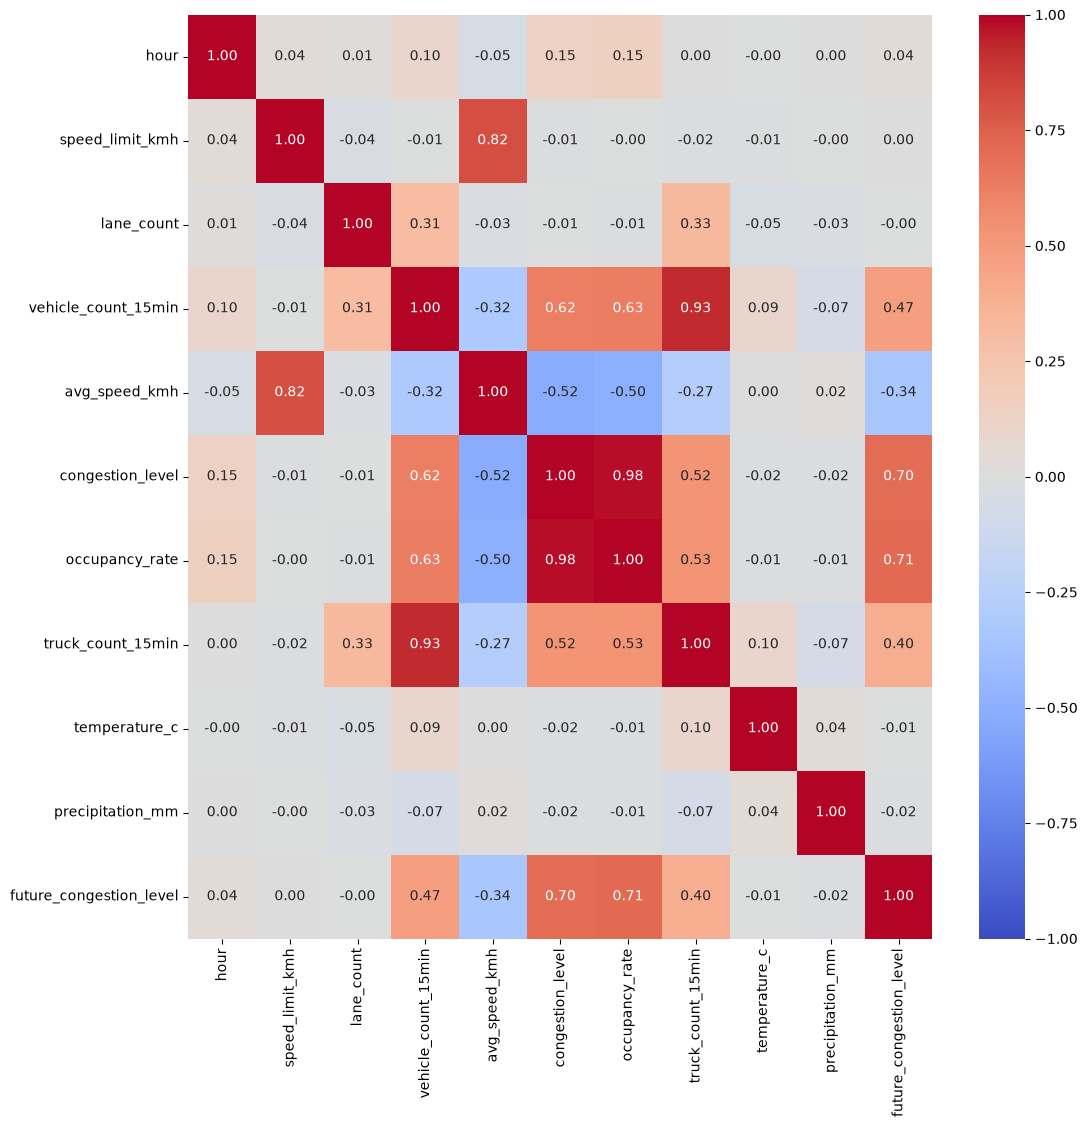

In [62]:
df_clean = df_processed.dropna()

df_clean["future_congestion_level"] = df_clean["future_congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})
df_clean["congestion_level"] = df_clean["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})

numeric_df = df_clean.select_dtypes(include=['float64','int64', 'int8'])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(12,12))
sns.heatmap(corr_matrix, annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt='.2f')
#plt.savefig('correlation.png')

In [67]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(x_train[["occupancy_rate"]], y_train)
accuracy_score(y_test, tree.predict(x_test[["occupancy_rate"]]))

0.6763285024154589

In [13]:
df["future_congestion_level"].value_counts()

future_congestion_level
free_flow    92425
moderate     38816
light        36835
heavy        31764
Name: count, dtype: int64

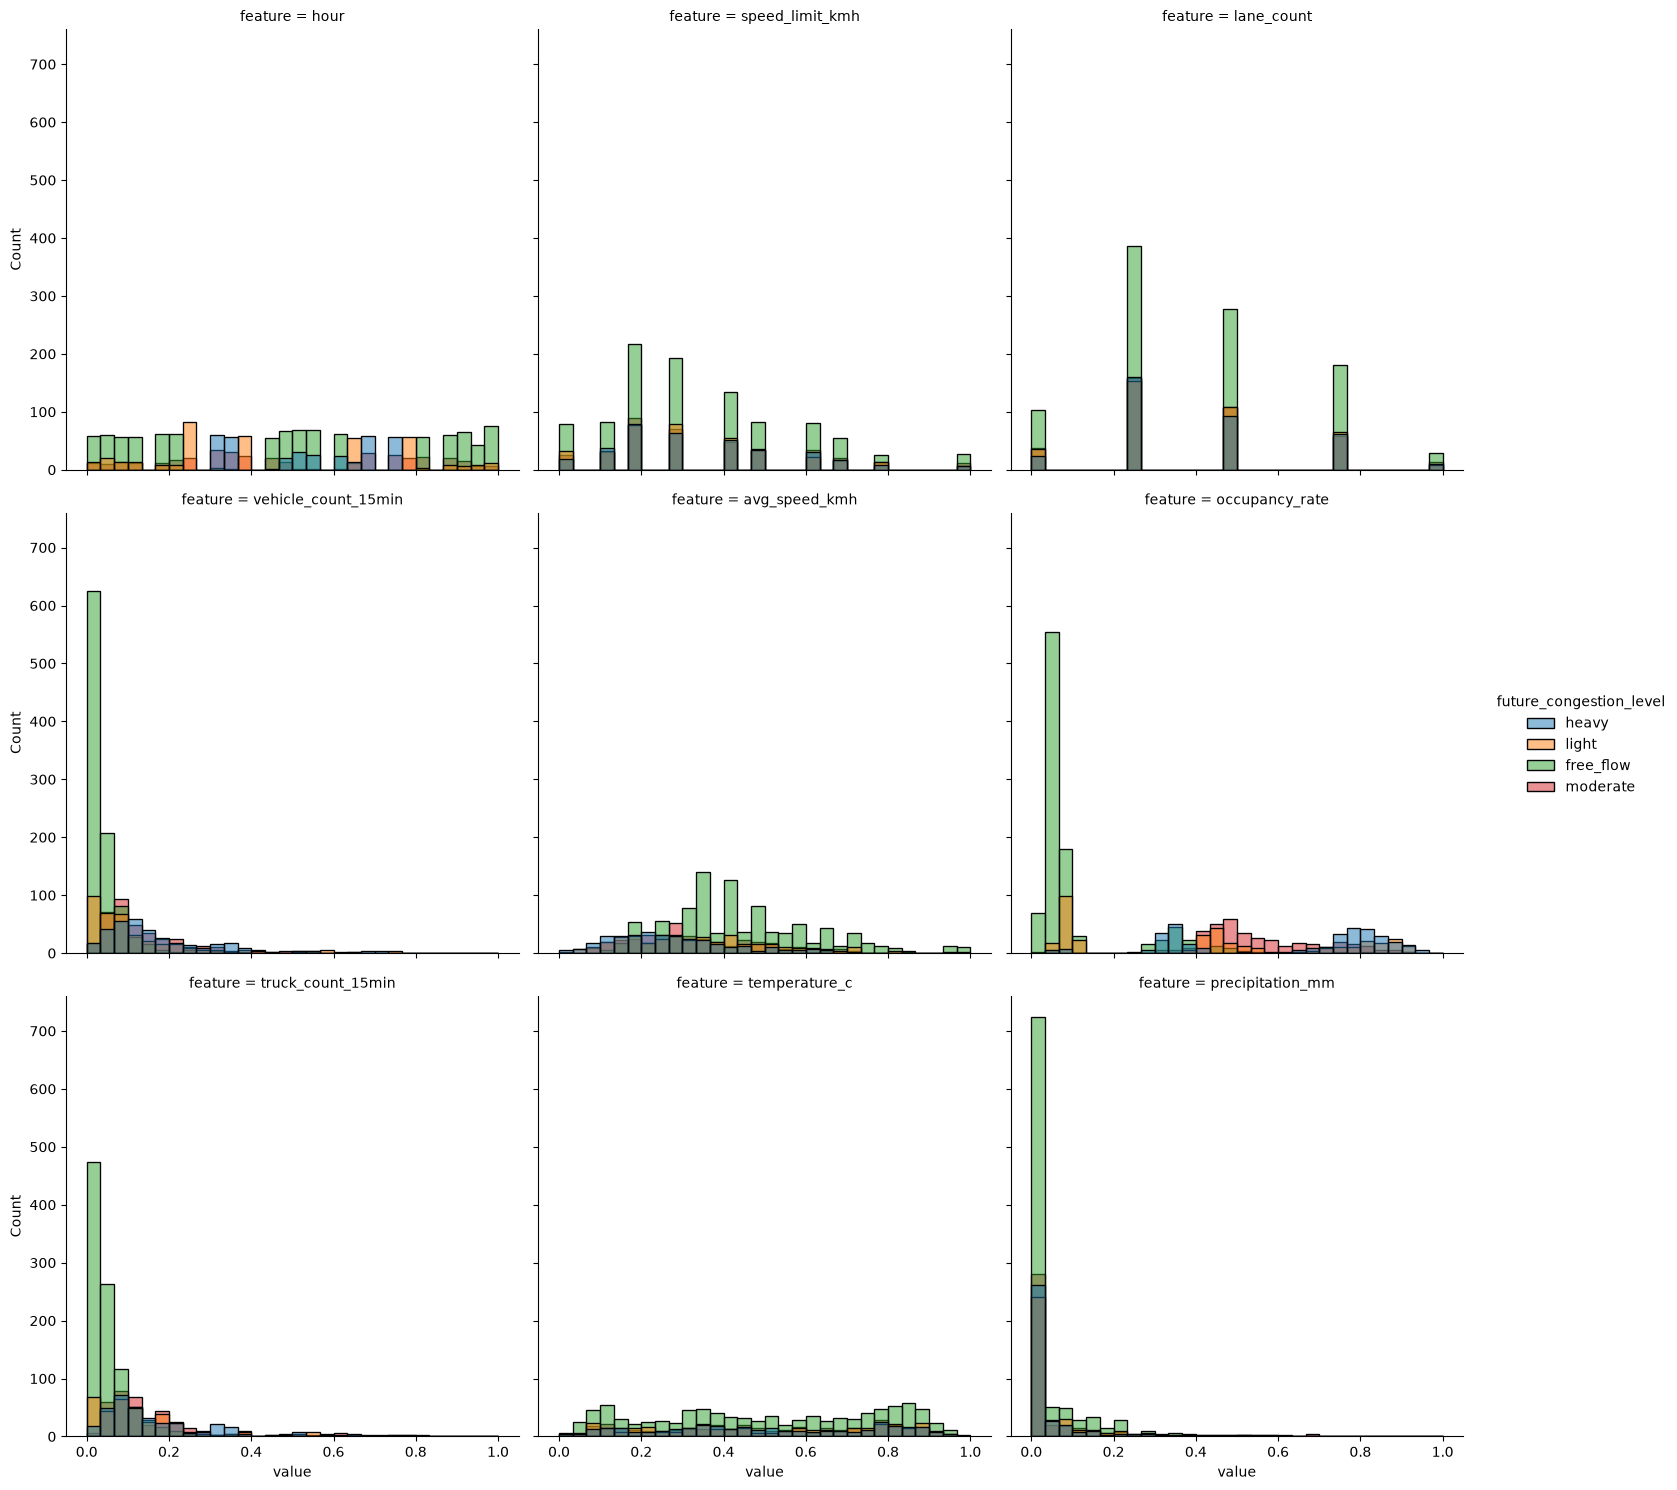

In [61]:
columns_to_drop = df_processed.select_dtypes(include=['string', 'bool']).columns.difference(['future_congestion_level'])
long_df = df_processed.drop(columns=columns_to_drop).melt(id_vars="future_congestion_level", var_name="feature", value_name="value")
sns.displot(data=long_df, x="value", col="feature", hue="future_congestion_level", col_wrap=3)
#plt.savefig('displot.png')

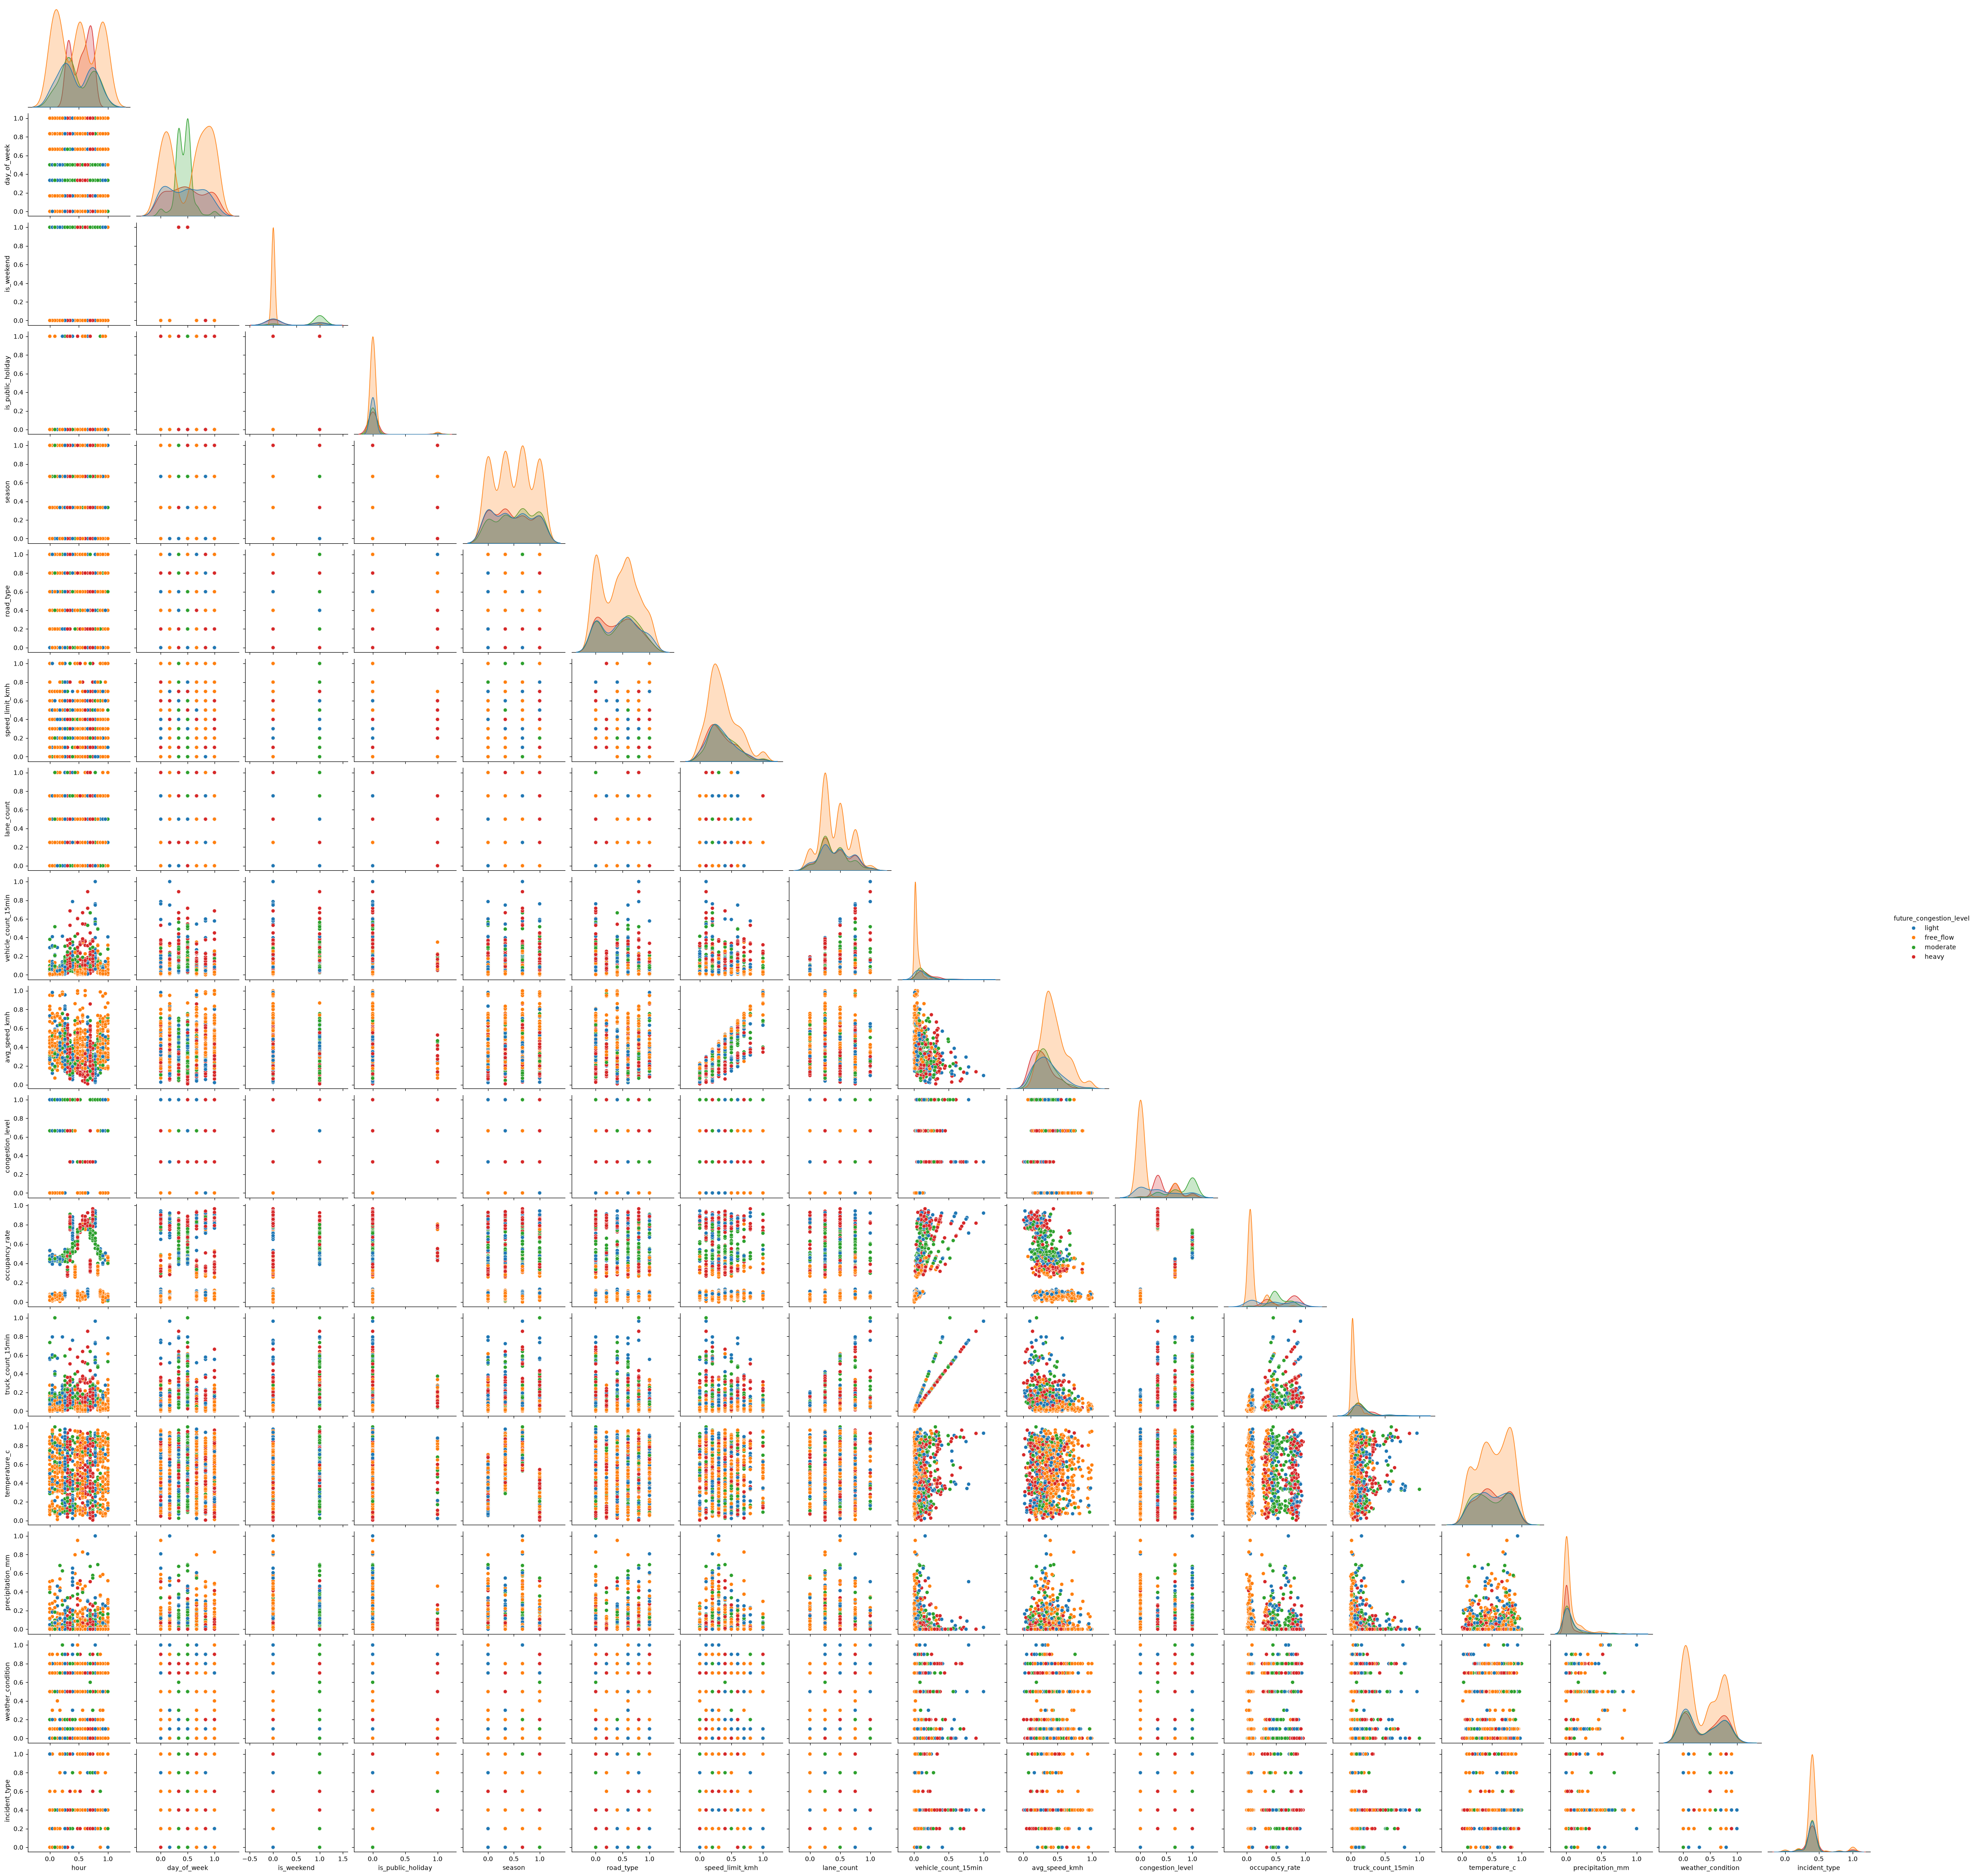

In [37]:
columns_to_drop = df_processed.select_dtypes(include=['string', 'bool']).columns.difference(['future_congestion_level'])
sns.pairplot(df_processed.drop(columns=columns_to_drop).sample(1000, random_state=42), hue="future_congestion_level", corner=True)
plt.savefig('pairplot.png')

In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 200000 entries, 165132 to 11258
Data columns (total 31 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   sensor_id                200000 non-null  str    
 1   city                     200000 non-null  str    
 2   country                  200000 non-null  str    
 3   district                 200000 non-null  str    
 4   timestamp                200000 non-null  str    
 5   date                     200000 non-null  str    
 6   hour                     200000 non-null  int64  
 7   day_of_week              200000 non-null  str    
 8   is_weekend               200000 non-null  bool   
 9   is_public_holiday        200000 non-null  bool   
 10  season                   200000 non-null  str    
 11  latitude                 200000 non-null  float64
 12  longitude                200000 non-null  float64
 13  road_type                200000 non-null  str    
 14  speed_limit_kmh 

<Axes: xlabel='day_of_week', ylabel='count'>

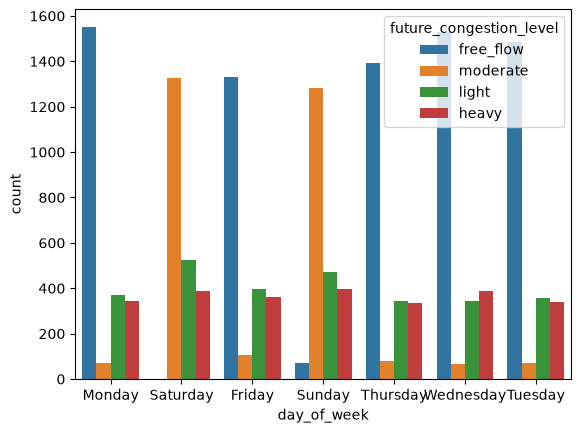

In [75]:
sns.countplot(data=df_processed, x='day_of_week', hue='future_congestion_level')

In [76]:
counts = df.groupby(['future_congestion_level', 'is_public_holiday']).size().unstack(fill_value=0)
print(counts[True] / counts[False])

future_congestion_level
free_flow    0.033471
heavy        0.033720
light        0.032214
moderate     0.025884
dtype: float64


<Axes: xlabel='hour', ylabel='Percent'>

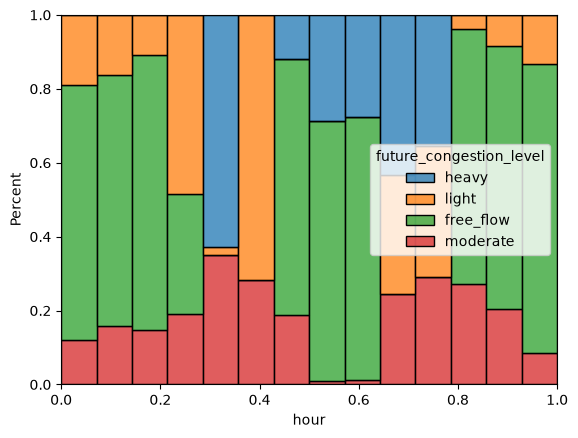

In [125]:
sns.histplot(
    data=df_processed,
    x='hour',
    hue='future_congestion_level',
    multiple='fill',
    stat='percent'
)

<Axes: xlabel='season', ylabel='Percent'>

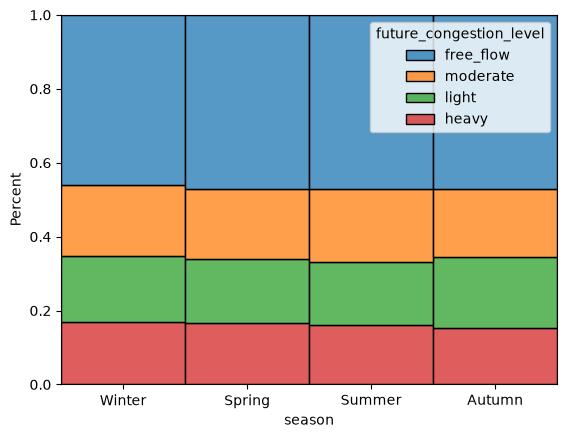

In [77]:
sns.histplot(data=df_processed,
    x='season',
    hue='future_congestion_level',
    multiple='fill',
    stat='percent'
)

<Axes: xlabel='road_type', ylabel='Percent'>

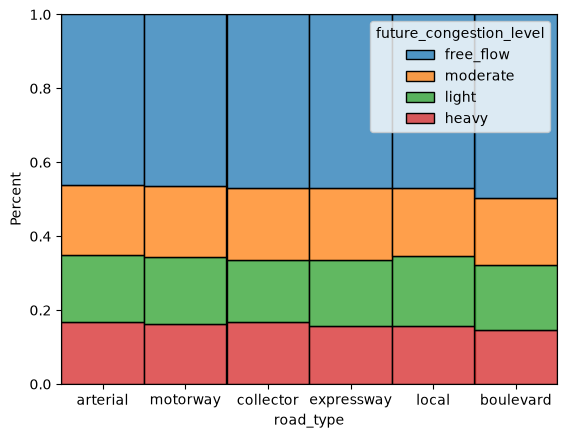

In [78]:
sns.histplot(data=df_processed, x='road_type', hue='future_congestion_level', multiple='fill', stat='percent')

<Axes: xlabel='weather_condition', ylabel='Percent'>

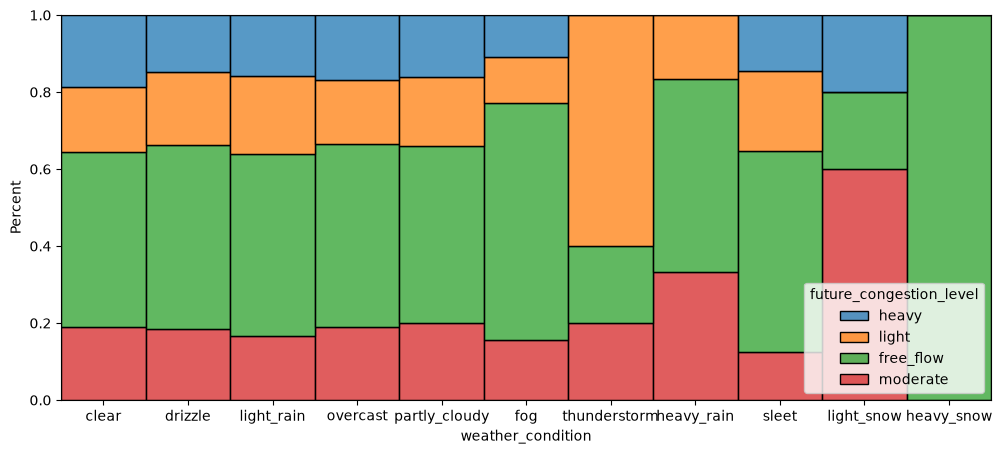

In [148]:
plt.figure(figsize=(12,5))
sns.histplot(data=df_processed, x='weather_condition', hue='future_congestion_level', multiple='fill', stat='percent')

<Axes: xlabel='incident_type', ylabel='Percent'>

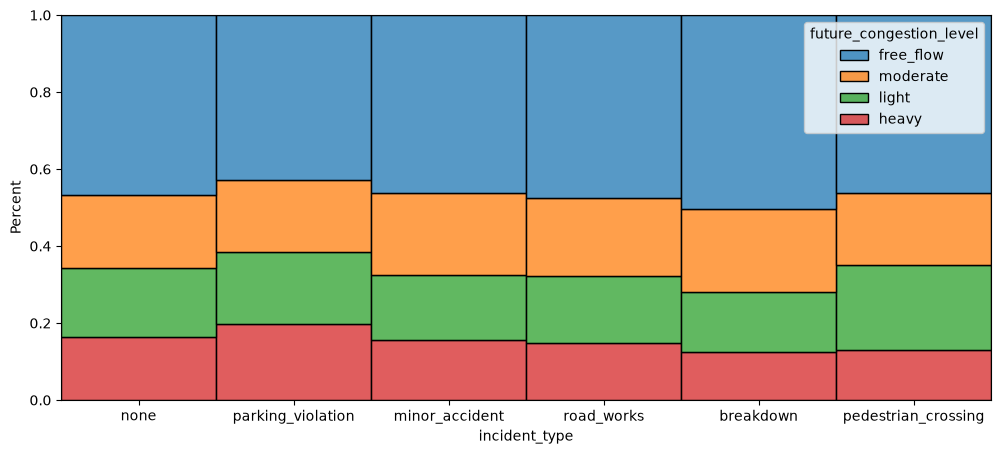

In [80]:
plt.figure(figsize=(12,5))
sns.histplot(data=df_processed, x='incident_type', hue='future_congestion_level', multiple='fill', stat='percent')